# Diversification in the Hong Kong Stock Market: Mean–Variance vs Equal-Weight

**Goal**

Compare an Equal-Weight (EW) portfolio against a Markowitz Mean–Variance (MV) portfolio on a Hong Kong equity universe.

**Key questions**
1) Does MV improve the risk–return tradeoff vs EW?
2) Does MV actually increase diversification, or does it concentrate weights?
3) How robust are the conclusions across reasonable scenario choices (lookback, constraints, covariance estimation)?

> We use Yahoo Finance data (yfinance), Jan 2023–Dec 2025 (optionally extend to 2026 for a freshness check).

## Imports and Set-up

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from pypfopt import expected_returns, risk_models, EfficientFrontier, exceptions

plt.rcParams["figure.figsize"] = (10, 5)

In [79]:
start = "2023-01-01"
end   = "2025-12-31"  

tickers = ["0005.HK","1299.HK","0700.HK","3690.HK","1113.HK","0016.HK","0291.HK","0669.HK","GC=F"]

name_map = {
    "0005.HK": "HSBC",
    "1299.HK": "AIA",
    "0700.HK": "Tencent",
    "3690.HK": "Meituan",
    "1113.HK": "CK Asset",
    "0016.HK": "Sun Hung Kai Prop.",
    "0291.HK": "CR Beer",
    "0669.HK": "Techtronic",
    "GC=F": "Gold",
}

sector_map = {
    "HSBC": "Finance",
    "AIA": "Finance",
    "Tencent": "Technology",
    "Meituan": "Technology",
    "CK Asset": "Real Estate",
    "Sun Hung Kai Prop.": "Real Estate",
    "CR Beer": "Consumer Goods",
    "Techtronic": "Consumer Goods",
    "Gold": "Commodity",
}

In [80]:
raw = yf.download(tickers, start=start, end=end, auto_adjust=False, progress=False)
prices = raw["Adj Close"].sort_index().dropna(how="all")

# Keep only dates where all assets exist (clean matrix)
prices = prices.dropna(how="any")

rets = prices.pct_change().dropna(how="any")

print("Prices:", prices.index.min(), "->", prices.index.max(), "| shape:", prices.shape)
print("Returns:", rets.index.min(), "->", rets.index.max(), "| shape:", rets.shape)

Prices: 2023-01-03 00:00:00 -> 2025-12-30 00:00:00 | shape: (714, 9)
Returns: 2023-01-04 00:00:00 -> 2025-12-30 00:00:00 | shape: (713, 9)


## EDA - Exploratory Data Analysis

We plot normalized performance (Start=100) to visualize dispersion across assets.
We provide:
- Linear scale plot
- Log scale plot (more comparable in % terms)

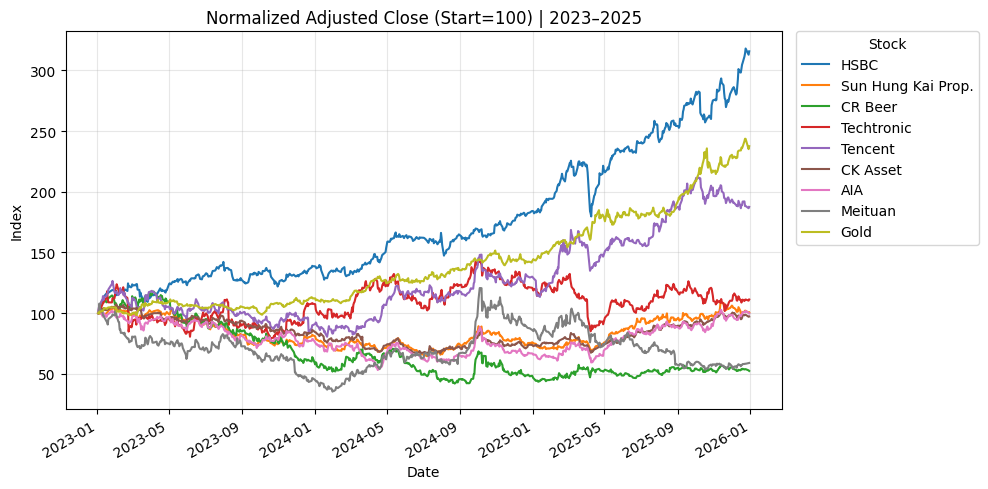

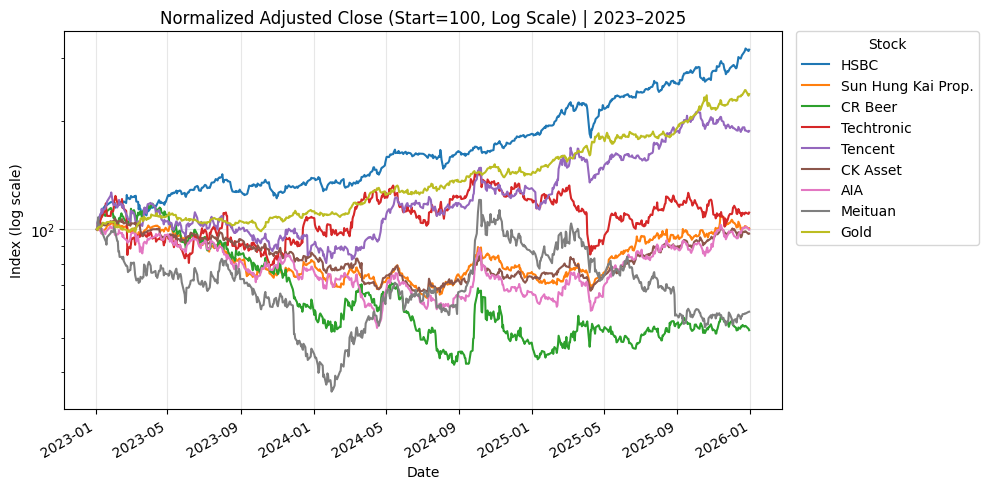

In [81]:
prices_named = prices.rename(columns=name_map)
norm = prices_named / prices_named.iloc[0] * 100

# Linear
ax = norm.plot()
ax.set_title("Normalized Adjusted Close (Start=100) | 2023–2025")
ax.set_xlabel("Date"); ax.set_ylabel("Index")
ax.grid(True, alpha=0.3)
ax.legend(title="Stock", bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
plt.tight_layout()
plt.show()

# Log
ax = norm.plot(logy=True)
ax.set_title("Normalized Adjusted Close (Start=100, Log Scale) | 2023–2025")
ax.set_xlabel("Date"); ax.set_ylabel("Index (log scale)")
ax.grid(True, alpha=0.3)
ax.legend(title="Stock", bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
plt.tight_layout()
plt.show()

The normalized price charts highlight a strong dispersion in performance across the 2023–2025 sample. On the **linear scale**, a few names (notably **HSBC**, and to a lesser extent **Tencent**) dominate the cumulative performance, while others (e.g., **CR Beer** and **Meituan**) lag behind. The **log-scale** view makes percentage moves more comparable and helps visualize volatility, drawdowns, and recovery phases across stocks.

This cross-sectional divergence motivates the portfolio comparison: **EW** spreads capital evenly across all assets, while **MV** may allocate more aggressively toward the assets (and sectors) that appear attractive based on estimated returns and the covariance structure.

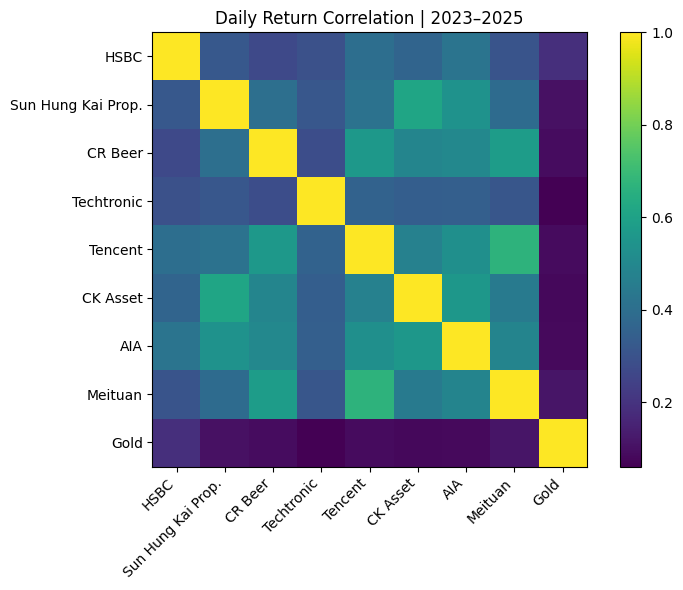

In [73]:
rets_named = rets.rename(columns=name_map)
corr = rets_named.corr()

plt.figure(figsize=(8,6))
plt.imshow(corr.values)
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Daily Return Correlation | 2023–2025")
plt.colorbar()
plt.tight_layout()
plt.show()

Overall, correlations are **moderate rather than extreme**, suggesting there is meaningful diversification potential across the selected names. A few pairs stand out with **higher co-movement**, especially within related segments: **Tencent–Meituan** shows one of the strongest positive correlations (both large tech/platform names), and the **real-estate names** (Sun Hung Kai Properties and CK Asset) also display relatively higher correlation with each other compared to most cross-sector pairs. 

In contrast, some stocks (e.g., **Techtronic**) appear **less correlated** with the rest of the universe, which can improve diversification when included in a portfolio. These patterns matter for the EW vs MV comparison: EW benefits mechanically from mixing assets, while MV may tilt toward combinations that reduce covariance (lower internal correlation) or, if expected returns dominate, concentrate in a subset of more correlated assets.

## Portfolios construction

We build:
1) **Equal-Weight (EW)** portfolio: each asset receives a weight of **1/N**, rebalanced **monthly**.  
2) **Mean–Variance (MV)** portfolio: Markowitz optimization, rebalanced **monthly**, with inputs estimated using a **rolling lookback window**.

Implementation choices and motivation:
- **Monthly rebalancing (month-end trading day)** --> it is realistic to implement and reduces noise/overtrading compared to very frequent re-optimization.  
- **Rolling lookback = 252 trading days (~1 year)** --> it estimates expected returns and covariances using *only past data*, limiting **look-ahead bias** and capturing recent market conditions.  
- **Long-only constraint (w ≥ 0)** --> short-selling may be infeasible in practice and unconstrained MV solutions can produce unstable offsetting positions.  
- **Fully invested constraint (∑w = 1)** --> it ensures the portfolio is always comparable across time and avoids unintended leverage or cash positions.  
- **Weight cap (e.g., 35%)** --> MV optimizations can become overly concentrated due to estimation error; the cap improves robustness and enforces diversification.  
- **Max Sharpe objective with fallback to minimum volatility** --> the max-Sharpe problem can be infeasible under constraints in some windows; the fallback guarantees a feasible solution and keeps the backtest continuous.

In [ ]:
lookback = 252
rf = 0.0
weight_cap = 0.32 

rebalance_dates = rets.resample("ME").last().index
rebalance_dates = [d for d in rebalance_dates if d in rets.index]
rebalance_dates = [d for d in rebalance_dates if rets.index.get_loc(d) >= lookback]

assets = rets.columns.tolist()
N = len(assets)

w_ew = pd.DataFrame(index=rebalance_dates, columns=assets, dtype=float)
w_mv = pd.DataFrame(index=rebalance_dates, columns=assets, dtype=float)

for d in rebalance_dates:
    loc = rets.index.get_loc(d)
    window_idx = rets.index[loc - lookback: loc]
    window_prices = prices.loc[window_idx]

   
    w_ew.loc[d] = np.repeat(1.0 / N, N)

    mu = expected_returns.mean_historical_return(window_prices, frequency=252)
    S  = risk_models.CovarianceShrinkage(window_prices).ledoit_wolf()

    ef = EfficientFrontier(mu, S, weight_bounds=(0.0, 1.0))
    if weight_cap is not None:
        ef.add_constraint(lambda w: w <= weight_cap)

    try:
        ef.max_sharpe(risk_free_rate=rf)
    except exceptions.OptimizationError:
        ef = EfficientFrontier(mu, S, weight_bounds=(0.0, 1.0))
        if weight_cap is not None:
            ef.add_constraint(lambda w: w <= weight_cap)
        ef.min_volatility()

    w = ef.clean_weights()
    w_mv.loc[d] = pd.Series(w).reindex(assets).fillna(0.0)

print("Weight NaN fraction (MV):", w_mv.isna().mean().mean())
print("Weight sums (MV) head:\n", w_mv.sum(axis=1).head())

Weight NaN fraction (MV): 0.0
Weight sums (MV) head:
 2024-01-31    0.99999
2024-02-29    1.00001
2024-04-30    1.00000
2024-05-31    1.00000
2024-07-31    1.00000
dtype: float64


**Backtest logic (how performance is computed).** Portfolio weights are updated only at the monthly rebalance dates (month-end trading days). Between two rebalances, weights are held constant (buy-and-hold within the month). To compute the daily portfolio return series, monthly weights are forward-filled to each trading day and applied to daily asset returns as a weighted sum, 
$$
r_{p,d}=\sum_i w_{i,d}\,r_{i,d}.
$$
For the MV strategy, weights at each rebalance date are estimated using a rolling lookback window that ends at that date, so inputs are based on past data only and the backtest avoids look-ahead bias; consequently, MV performance starts only once sufficient lookback history is available.

In [46]:
def weights_to_daily_portfolio_returns(rets_df: pd.DataFrame, w_rebal: pd.DataFrame) -> pd.Series:
    w_daily = w_rebal.reindex(rets_df.index).ffill()
    w_daily = w_daily.loc[w_rebal.index[0]:]
    return (w_daily * rets_df.loc[w_daily.index]).sum(axis=1)

ew_port = weights_to_daily_portfolio_returns(rets, w_ew)
mv_port = weights_to_daily_portfolio_returns(rets, w_mv)

print("Backtest range EW:", ew_port.index.min(), "->", ew_port.index.max())
print("Backtest range MV:", mv_port.index.min(), "->", mv_port.index.max())

Backtest range EW: 2024-01-31 00:00:00 -> 2025-12-30 00:00:00
Backtest range MV: 2024-01-31 00:00:00 -> 2025-12-30 00:00:00


## Results - performance comparison (EW vs Mean–Variance)

In this section we compare the two strategies using (i) the **cumulative performance index** (Start = 100) to visualize how portfolio value evolves over time, and (ii) standard **risk–return metrics** (annualized return, annualized volatility, Sharpe ratio, and maximum drawdown) to summarize performance and downside risk in a compact way.

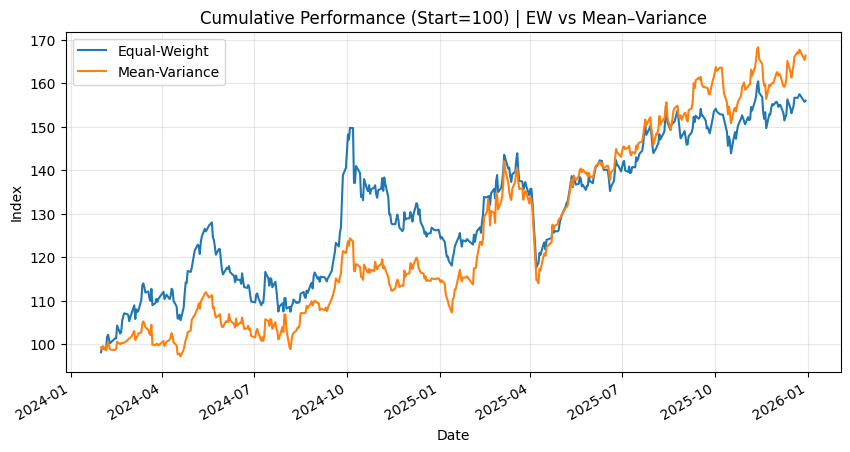

In [47]:
cum = pd.DataFrame({
    "Equal-Weight": (1 + ew_port).cumprod() * 100,
    "Mean-Variance": (1 + mv_port).cumprod() * 100
})

ax = cum.plot()
ax.set_title("Cumulative Performance (Start=100) | EW vs Mean–Variance")
ax.set_xlabel("Date"); ax.set_ylabel("Index")
ax.grid(True, alpha=0.3)
plt.show()

In [48]:
def max_drawdown(r):
    wealth = (1 + r).cumprod()
    peak = wealth.cummax()
    dd = wealth / peak - 1
    return dd.min()

def ann_metrics(r, rf=0.0):
    ann_ret = (1 + r).prod() ** (252 / len(r)) - 1
    ann_vol = r.std() * np.sqrt(252)
    sharpe = np.nan if ann_vol == 0 else (ann_ret - rf) / ann_vol
    mdd = max_drawdown(r)
    return ann_ret, ann_vol, sharpe, mdd

rows = []
for name, series in [("Equal-Weight", ew_port), ("Mean-Variance", mv_port)]:
    ar, av, sh, mdd = ann_metrics(series.dropna(), rf=rf)
    rows.append([name, ar, av, sh, mdd])

metrics = pd.DataFrame(rows, columns=["Portfolio","Ann Return","Ann Vol","Sharpe","Max Drawdown"])
metrics

,Portfolio,Ann Return,Ann Vol,Sharpe,Max Drawdown
0,Equal-Weight,0.269376,0.238981,1.127186,-0.214088
1,Mean-Variance,0.313939,0.223202,1.406524,-0.197925


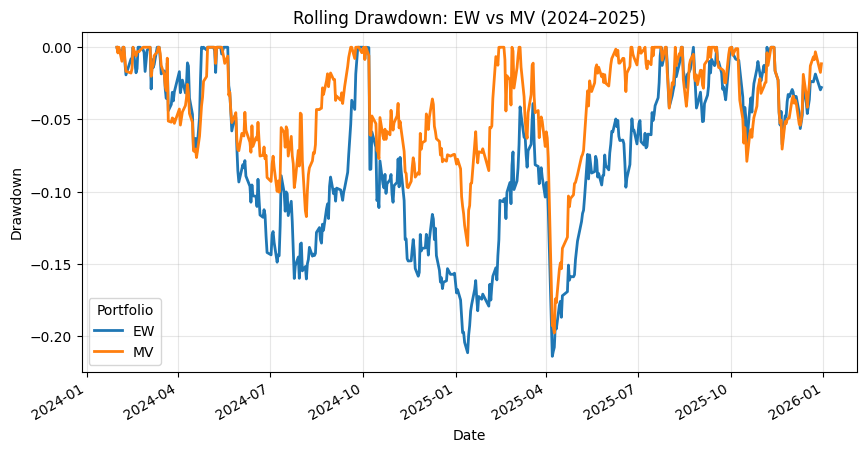

In [49]:
cum_ew = (1 + ew_port).cumprod()
cum_mv = (1 + mv_port).cumprod()

dd_ew = cum_ew / cum_ew.cummax() - 1
dd_mv = cum_mv / cum_mv.cummax() - 1

ax = pd.DataFrame({
    "EW": dd_ew,
    "MV": dd_mv
}).plot(
    figsize=(10, 5),
    linewidth=2,
    title="Rolling Drawdown: EW vs MV (2024–2025)"
)

ax.set_xlabel("Date")
ax.set_ylabel("Drawdown")
ax.legend(title="Portfolio")
ax.grid(True, alpha=0.3)

**Findings** 

The cumulative plot shows that both portfolios experience similar market phases, but the Mean–Variance (MV) strategy tends to recover more strongly in the later part of the sample and finishes above the Equal-Weight (EW) benchmark. This is consistent with the summary statistics: EW achieves an annualized return of **26.94%** with volatility **23.90%**, while MV reaches a higher annualized return of **31.48%** with slightly lower volatility (**22.29%**). As a result, MV delivers a higher **Sharpe ratio** (**1.41** vs **1.13**), indicating better risk-adjusted performance. MV also shows a smaller **maximum drawdown** (**−19.60%** vs **−21.41%**), suggesting improved downside protection relative to EW over the evaluated period.

## Downside Risk: Value-at-Risk (VaR) and Expected Shortfall (ES)

In addition to return, volatility, Sharpe ratio, and maximum drawdown, we evaluate downside risk using Value-at-Risk (VaR) and Expected Shortfall (ES). Following standard market risk practice, we report both historical (non-parametric) and delta-normal (parametric) VaR for the Equal-Weight (EW), Mean–Variance (MV), and benchmark portfolios. This extends the risk analysis beyond overall volatility by focusing directly on potential losses in adverse scenarios.

In [50]:
from scipy.stats import norm

def historical_var(r: pd.Series, alpha=0.95):
    """
    Historical VaR on returns.
    Returns a positive loss number.
    Example: alpha=0.95 -> 95% VaR
    """
    loss = -r.dropna()
    return loss.quantile(alpha)

def historical_es(r: pd.Series, alpha=0.95):
    """
    Historical Expected Shortfall on returns.
    Returns a positive loss number.
    """
    loss = -r.dropna()
    var = loss.quantile(alpha)
    tail = loss[loss >= var]
    return tail.mean()

def delta_normal_var(r: pd.Series, alpha=0.95, mean_zero=True):
    """
    Parametric (delta-normal) VaR on returns.
    Returns a positive loss number.
    """
    x = r.dropna()
    mu = 0.0 if mean_zero else x.mean()
    sigma = x.std(ddof=1)
    z = norm.ppf(alpha)
    # Loss VaR = -(mu - z*sigma) = z*sigma - mu
    return z * sigma - mu

def scale_var(var_1d, horizon_days=10):
    """
    Square-root-of-time scaling for delta-normal VaR.
    """
    return np.sqrt(horizon_days) * var_1d

def var_exceptions(r: pd.Series, var_level):
    """
    Counts days where realized loss exceeds VaR threshold.
    """
    loss = -r.dropna()
    return int((loss > var_level).sum()), int(loss.shape[0])

In [51]:
risk_rows = []

series_map = {
    "EW": ew_port,
    "MV (cap 35%)": mv_port,
}

# Add HSI only if benchmark has already been computed in the notebook
if "bench_b" in globals():
    series_map["Hang Seng (HSI)"] = bench_b

for name, series in series_map.items():
    hvar95 = historical_var(series, 0.95)
    hvar99 = historical_var(series, 0.99)
    hes95  = historical_es(series, 0.95)
    hes99  = historical_es(series, 0.99)

    dvar95_1d = delta_normal_var(series, 0.95, mean_zero=True)
    dvar99_1d = delta_normal_var(series, 0.99, mean_zero=True)

    dvar95_10d = scale_var(dvar95_1d, 10)
    dvar99_10d = scale_var(dvar99_1d, 10)

    exc95, n95 = var_exceptions(series, hvar95)
    exc99, n99 = var_exceptions(series, hvar99)

    risk_rows.append({
        "Series": name,
        "Hist VaR 95% (1d)": hvar95,
        "Hist VaR 99% (1d)": hvar99,
        "Hist ES 95% (1d)": hes95,
        "Hist ES 99% (1d)": hes99,
        "Delta-Normal VaR 95% (1d)": dvar95_1d,
        "Delta-Normal VaR 99% (1d)": dvar99_1d,
        "Delta-Normal VaR 95% (10d)": dvar95_10d,
        "Delta-Normal VaR 99% (10d)": dvar99_10d,
        "Exceptions > Hist VaR 95%": exc95,
        "Exceptions > Hist VaR 99%": exc99,
        "Obs": len(series.dropna())
    })

risk_summary = pd.DataFrame(risk_rows).set_index("Series")

In [52]:
risk_summary_pct = risk_summary.copy()

pct_cols = [c for c in risk_summary_pct.columns if "(1d)" in c or "(10d)" in c]
risk_summary_pct[pct_cols] = risk_summary_pct[pct_cols] * 100

risk_summary_pct.style.format({
    **{c: "{:.2f}%" for c in pct_cols},
    "Exceptions > Hist VaR 95%": "{:.0f}",
    "Exceptions > Hist VaR 99%": "{:.0f}",
    "Obs": "{:.0f}",
})

,Hist VaR 95% (1d),Hist VaR 99% (1d),Hist ES 95% (1d),Hist ES 99% (1d),Delta-Normal VaR 95% (1d),Delta-Normal VaR 99% (1d),Delta-Normal VaR 95% (10d),Delta-Normal VaR 99% (10d),Exceptions > Hist VaR 95%,Exceptions > Hist VaR 99%,Obs
Series,,,,,,,,,,,
EW,1.90%,2.93%,3.10%,6.04%,2.48%,3.50%,7.83%,11.07%,24,5,470
MV (cap 35%),1.81%,3.42%,2.96%,5.96%,2.31%,3.27%,7.31%,10.34%,24,5,470
Hang Seng (HSI),1.90%,2.68%,3.07%,6.48%,2.54%,3.59%,8.03%,11.35%,24,5,470


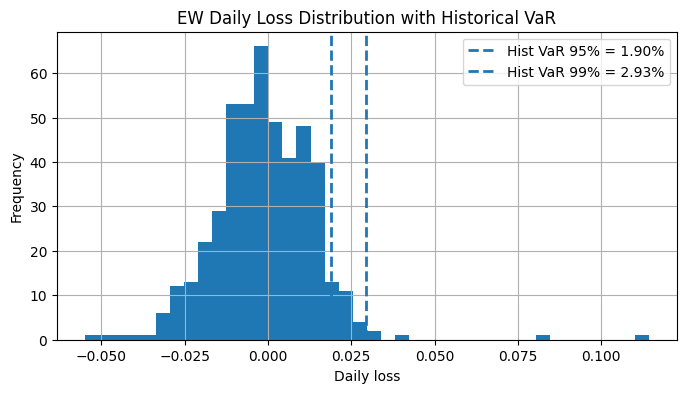

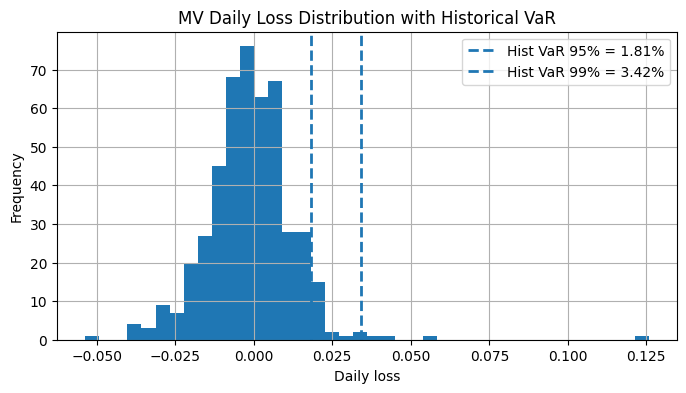

In [53]:
def plot_loss_distribution_with_var(r: pd.Series, title: str):
    loss = -r.dropna()
    var95 = historical_var(r, 0.95)
    var99 = historical_var(r, 0.99)

    ax = loss.hist(bins=40, figsize=(8,4))
    ax.axvline(var95, linestyle="--", linewidth=2, label=f"Hist VaR 95% = {var95:.2%}")
    ax.axvline(var99, linestyle="--", linewidth=2, label=f"Hist VaR 99% = {var99:.2%}")
    ax.set_title(title)
    ax.set_xlabel("Daily loss")
    ax.set_ylabel("Frequency")
    ax.legend()
    plt.show()

plot_loss_distribution_with_var(ew_port, "EW Daily Loss Distribution with Historical VaR")
plot_loss_distribution_with_var(mv_port, "MV Daily Loss Distribution with Historical VaR")

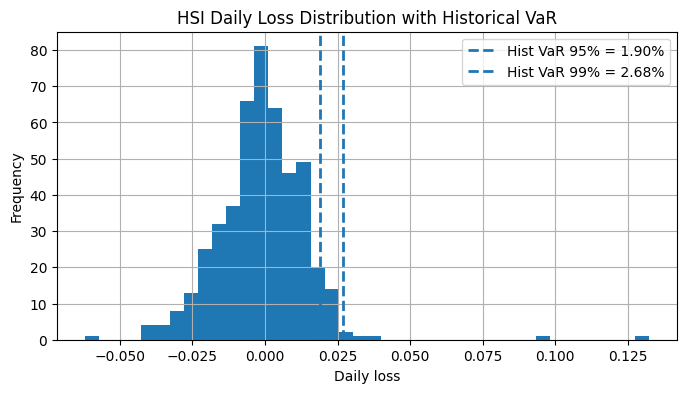

In [54]:
if "bench_b" in globals():
    plot_loss_distribution_with_var(bench_b, "HSI Daily Loss Distribution with Historical VaR")

In [55]:
def max_drawdown(r):
    wealth = (1 + r).cumprod()
    peak = wealth.cummax()
    dd = wealth / peak - 1
    return dd.min()

def ann_return(r):
    x = r.dropna()
    return (1 + x).prod() ** (252 / len(x)) - 1

def ann_vol(r):
    return r.dropna().std(ddof=1) * np.sqrt(252)

def sharpe_ratio(r, rf=0.0):
    ar = ann_return(r)
    av = ann_vol(r)
    return np.nan if av == 0 else (ar - rf) / av

summary_rows = []

series_map = {
    "EW": ew_port,
    "MV (cap 35%)": mv_port,
}

if "bench_b" in globals():
    series_map["Hang Seng (HSI)"] = bench_b

for name, series in series_map.items():
    summary_rows.append({
        "Series": name,
        "Ann Return": ann_return(series),
        "Ann Vol": ann_vol(series),
        "Sharpe": sharpe_ratio(series, rf=0.0),
        "Max Drawdown": max_drawdown(series),
        "Hist VaR 95% (1d)": historical_var(series, 0.95),
        "Hist VaR 99% (1d)": historical_var(series, 0.99),
        "Hist ES 95% (1d)": historical_es(series, 0.95),
        "Hist ES 99% (1d)": historical_es(series, 0.99),
    })

performance_risk_table = pd.DataFrame(summary_rows).set_index("Series")

In [56]:
performance_risk_table_pct = performance_risk_table.copy()
for c in performance_risk_table_pct.columns:
    performance_risk_table_pct[c] = performance_risk_table_pct[c] * 100 if c != "Sharpe" else performance_risk_table_pct[c]

performance_risk_table_pct.style.format({
    "Ann Return": "{:.2f}%",
    "Ann Vol": "{:.2f}%",
    "Sharpe": "{:.3f}",
    "Max Drawdown": "{:.2f}%",
    "Hist VaR 95% (1d)": "{:.2f}%",
    "Hist VaR 99% (1d)": "{:.2f}%",
    "Hist ES 95% (1d)": "{:.2f}%",
    "Hist ES 99% (1d)": "{:.2f}%"
})

,Ann Return,Ann Vol,Sharpe,Max Drawdown,Hist VaR 95% (1d),Hist VaR 99% (1d),Hist ES 95% (1d),Hist ES 99% (1d)
Series,,,,,,,,
EW,26.94%,23.90%,1.127,-21.41%,1.90%,2.93%,3.10%,6.04%
MV (cap 35%),31.39%,22.32%,1.407,-19.79%,1.81%,3.42%,2.96%,5.96%
Hang Seng (HSI),30.65%,24.50%,1.251,-19.95%,1.90%,2.68%,3.07%,6.48%


## Diversification diagnostics

Performance alone does not guarantee diversification. In this section we evaluate *how* EW and MV achieve their results by measuring:
- **Asset-level diversification:** how concentrated weights are across individual stocks (HHI, top weights), who drives the portfolio, and how stable weights are over time (turnover).
- **Sector-level diversification:** how capital is distributed across sectors, and whether MV concentrates the portfolio into a small subset of industries.
- **Internal correlation:** a portfolio-level measure of co-movement that captures “clustering risk” among holdings.

Together, these diagnostics help distinguish between improved risk-adjusted returns driven by true diversification vs. improved performance driven by concentration in a few names or sectors.

### Asset-level diversification

We first inspect diversification across individual stocks. We compare EW (mechanically diversified) with MV (optimization-driven) using:
- **Holdings snapshot:** MV vs EW weights at the latest rebalance date.
- **Concentration metrics:** Herfindahl–Hirschman Index (HHI) and top-1/top-2 weights over time.
- **Weight dynamics:** which assets drive MV allocations and whether the optimizer consistently hits the weight cap.
- **Turnover:** how much the MV portfolio changes at each rebalance (a proxy for trading intensity and stability).

In [57]:
w_mv_named = w_mv.rename(columns=name_map)
w_ew_named = w_ew.rename(columns=name_map)

last_date = w_mv_named.index[-1]
weights_compare = pd.DataFrame({
    "MV weight": w_mv_named.loc[last_date],
    "EW weight": w_ew_named.loc[last_date],
}).sort_values("MV weight", ascending=False)

weights_compare["MV - EW"] = weights_compare["MV weight"] - weights_compare["EW weight"]
weights_compare.round(4)

,MV weight,EW weight,MV - EW
HSBC,0.4000,0.125,0.2750
Tencent,0.3273,0.125,0.2023
CK Asset,0.2515,0.125,0.1265
Sun Hung Kai Prop.,0.0212,0.125,-0.1038
CR Beer,0.0000,0.125,-0.1250
Techtronic,0.0000,0.125,-0.1250
AIA,0.0000,0.125,-0.1250
Meituan,0.0000,0.125,-0.1250


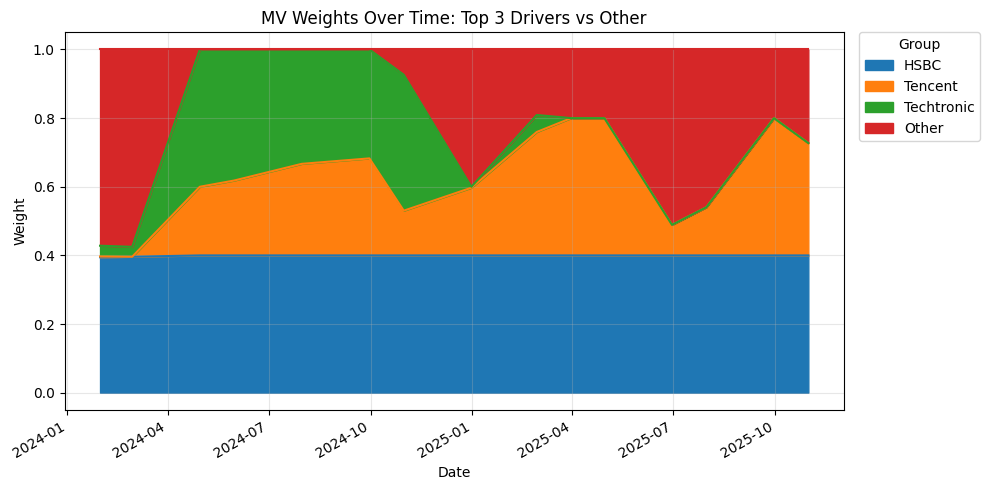

In [58]:
k = 3
topk = w_mv_named.mean().sort_values(ascending=False).head(k).index

w_top = w_mv_named[topk].copy()
w_top["Other"] = 1 - w_top.sum(axis=1)

ax = w_top.plot(kind="area", stacked=True, figsize=(10,5))
ax.set_title(f"MV Weights Over Time: Top {k} Drivers vs Other")
ax.set_xlabel("Date")
ax.set_ylabel("Weight")
ax.grid(True, alpha=0.3)
ax.legend(title="Group", bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
plt.tight_layout()
plt.show()

**Weights distribution and weight dynamics (drivers)**

The EW benchmark allocates a constant **1/N** to each stock, ensuring mechanical diversification. In contrast, the MV portfolio displays a strongly **uneven weight distribution**. In the latest rebalance snapshot, MV concentrates most capital in a small subset of names (with the largest weights reaching the 35% cap), while several assets receive near-zero allocations.  

The “Top drivers vs Other” area chart shows that MV weights are **time-varying** but consistently dominated by a few key holdings. This indicates that MV performance is primarily driven by a small number of stocks rather than broad exposure across the full universe.

In [59]:
def hhi(row: pd.Series) -> float:
    w = row.fillna(0).values
    return float(np.sum(w**2))

concentration = pd.DataFrame(index=w_mv_named.index)
concentration["MV_HHI"]  = w_mv_named.apply(hhi, axis=1)
concentration["MV_top1"] = w_mv_named.max(axis=1)
concentration["MV_top2"] = w_mv_named.apply(lambda r: np.sort(r.values)[-2:].sum(), axis=1)

N_assets = w_mv_named.shape[1]
concentration["EW_HHI"]  = 1 / N_assets
concentration["EW_top1"] = 1 / N_assets
concentration["EW_top2"] = 2 / N_assets

concentration["MV_effN"] = 1 / concentration["MV_HHI"]
concentration["EW_effN"] = 1 / concentration["EW_HHI"]

concentration.tail().round(4)

,MV_HHI,MV_top1,MV_top2,EW_HHI,EW_top1,EW_top2,MV_effN,EW_effN
2025-04-30,0.3471,0.4,0.8000,0.125,0.125,0.25,2.8806,8.0
2025-06-30,0.3395,0.4,0.8000,0.125,0.125,0.25,2.9453,8.0
2025-07-31,0.3433,0.4,0.8000,0.125,0.125,0.25,2.9132,8.0
2025-09-30,0.3401,0.4,0.8000,0.125,0.125,0.25,2.9400,8.0
2025-10-31,0.3308,0.4,0.7273,0.125,0.125,0.25,3.0228,8.0


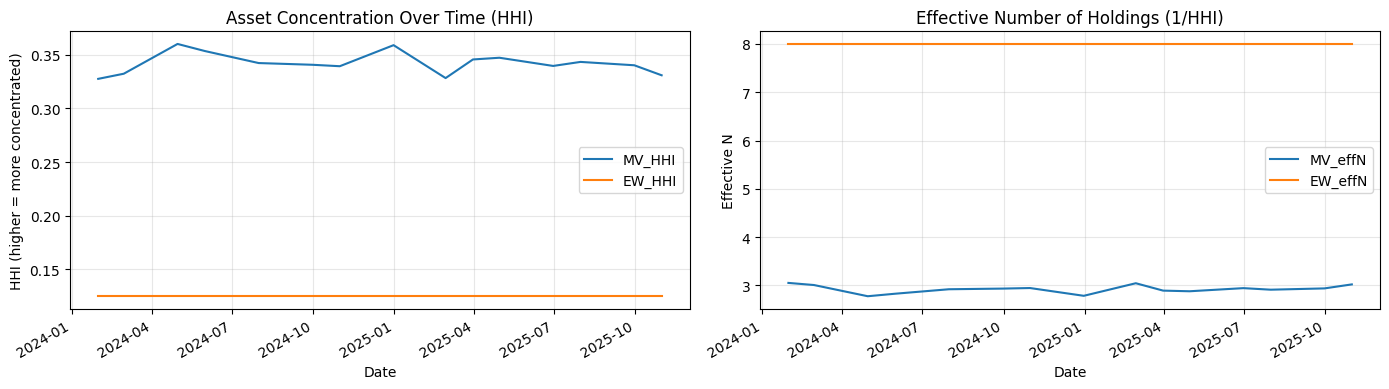

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharex=True)

concentration[["MV_HHI", "EW_HHI"]].plot(ax=axes[0])
axes[0].set_title("Asset Concentration Over Time (HHI)")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("HHI (higher = more concentrated)")
axes[0].grid(True, alpha=0.3)

concentration[["MV_effN", "EW_effN"]].plot(ax=axes[1])
axes[1].set_title("Effective Number of Holdings (1/HHI)")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Effective N")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Concentration (Top weights, HHI, and effective number of holdings)**

To quantify diversification at the asset level, we track **top-1/top-2 weights** and the **Herfindahl–Hirschman Index (HHI)** over time. EW has constant concentration by construction (HHI = 1/N), whereas MV exhibits substantially higher HHI values, confirming stronger single-name concentration. The fact that MV’s top-1 weight frequently equals the **35% cap** suggests the constraint is binding and the unconstrained solution would likely be even more concentrated.  

We also report the **effective number of holdings** (EffN = 1/HHI) as an intuitive measure of “how many stocks” the portfolio behaves like. While EW remains at **N** effective holdings, MV typically behaves like a portfolio with only **~3–4 effective holdings**, reflecting materially lower diversification at the asset level.

In [61]:
turnover_mv = (w_mv.diff().abs().sum(axis=1) / 2).dropna()

turnover_mv.describe()

count    15.000000
mean      0.165132
std       0.169146
min       0.000000
25%       0.032755
50%       0.143110
75%       0.258780
max       0.574965
dtype: float64

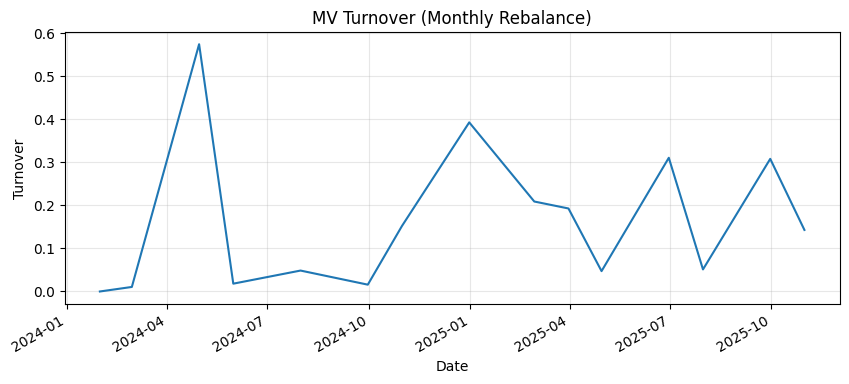

In [62]:
ax = turnover_mv.plot(figsize=(10,4))
ax.set_title("MV Turnover (Monthly Rebalance)")
ax.set_xlabel("Date")
ax.set_ylabel("Turnover")
ax.grid(True, alpha=0.3)
plt.show()

**Turnover and weight stability**

We compute MV **monthly turnover**
$$
\text{Turnover}_t = \frac{1}{2}\sum_i \left| w_{t,i} - w_{t-1,i} \right|.
$$ 
to assess the stability and practical implementability of the strategy. Turnover is **moderate on average** (mean ≈ 0.14; median ≈ 0.10), implying that a typical rebalance changes roughly 10–15% of the portfolio. However, the series also shows **occasional spikes** (max ≈ 0.61), indicating months where the optimizer substantially reshuffles allocations.  

These turnover spikes suggest that MV results may be more sensitive to transaction costs and estimation noise than EW, which remains stable by construction.

### Sector-level diversification

We next assess diversification at the sector level. Since the Hang Seng Index is often driven by a few dominant sectors, we compare EW vs MV in terms of:
- **Sector weight shares** over time (how capital is distributed across industries).
- **Top-3 sector share** as a direct measure of industry concentration.
This allows us to identify whether MV improves performance by concentrating into a small set of sectors or by maintaining balanced exposure.

In [63]:
stocks = w_mv_named.columns.tolist()
sectors = sorted(set(sector_map[s] for s in stocks))

def sector_weights(w_df_named: pd.DataFrame) -> pd.DataFrame:
    out = pd.DataFrame(index=w_df_named.index, columns=sectors, dtype=float)
    for sec in sectors:
        sec_stocks = [s for s in stocks if sector_map[s] == sec]
        out[sec] = w_df_named[sec_stocks].sum(axis=1)
    return out

sector_w_mv = sector_weights(w_mv_named)
sector_w_ew = sector_weights(w_ew_named)

sector_w_mv.tail().round(4)

,Consumer Goods,Finance,Real Estate,Technology
2025-04-30,0.0,0.4000,0.2000,0.4000
2025-06-30,0.0,0.4033,0.5076,0.0891
2025-07-31,0.0,0.4000,0.4596,0.1404
2025-09-30,0.0,0.4000,0.2000,0.4000
2025-10-31,0.0,0.4000,0.2727,0.3273


In [64]:
sector_last = pd.DataFrame({
    "MV sector weight": sector_w_mv.loc[last_date],
    "EW sector weight": sector_w_ew.loc[last_date],
}).sort_values("MV sector weight", ascending=False)

sector_last["MV - EW"] = sector_last["MV sector weight"] - sector_last["EW sector weight"]
sector_last.round(4)

,MV sector weight,EW sector weight,MV - EW
Finance,0.4000,0.25,0.1500
Technology,0.3273,0.25,0.0773
Real Estate,0.2727,0.25,0.0227
Consumer Goods,0.0000,0.25,-0.2500


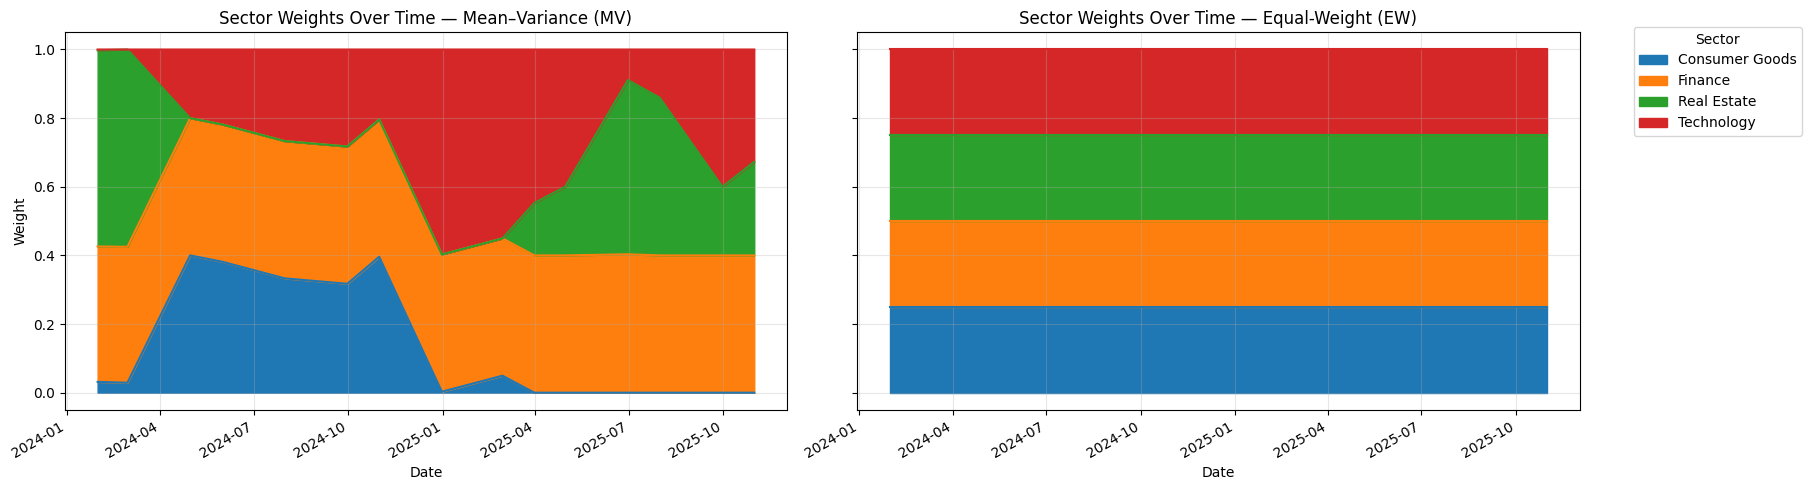

In [65]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)

sector_w_mv.plot(kind="area", stacked=True, ax=axes[0], legend=False)
axes[0].set_title("Sector Weights Over Time — Mean–Variance (MV)")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Weight")
axes[0].grid(True, alpha=0.3)

sector_w_ew.plot(kind="area", stacked=True, ax=axes[1], legend=False)
axes[1].set_title("Sector Weights Over Time — Equal-Weight (EW)")
axes[1].set_xlabel("Date")
axes[1].grid(True, alpha=0.3)

handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, title="Sector", bbox_to_anchor=(1.02, 0.95), loc="upper left")

plt.tight_layout()
plt.show()

**Sector weights over time**

EW remains perfectly balanced across sectors by construction (25% per sector, given two stocks per sector in our universe). In contrast, MV sector exposures are time-varying and often concentrate in a subset of industries. The MV allocation frequently tilts heavily toward **Finance, Technology, and Real Estate**, while **Consumer Goods** can drop close to zero in several rebalancing periods. This indicates that MV does not guarantee sector diversification: improvements in risk–return can be accompanied by stronger sector tilts and occasional exclusion of an entire sector.

In [66]:
top3_mv = sector_w_mv.apply(lambda r: np.sort(r.values)[-3:].sum(), axis=1)
top3_ew = sector_w_ew.apply(lambda r: np.sort(r.values)[-3:].sum(), axis=1)

top3 = pd.DataFrame({"MV_top3_sectors": top3_mv, "EW_top3_sectors": top3_ew})
top3.tail().round(4)

,MV_top3_sectors,EW_top3_sectors
2025-04-30,1.0,0.75
2025-06-30,1.0,0.75
2025-07-31,1.0,0.75
2025-09-30,1.0,0.75
2025-10-31,1.0,0.75


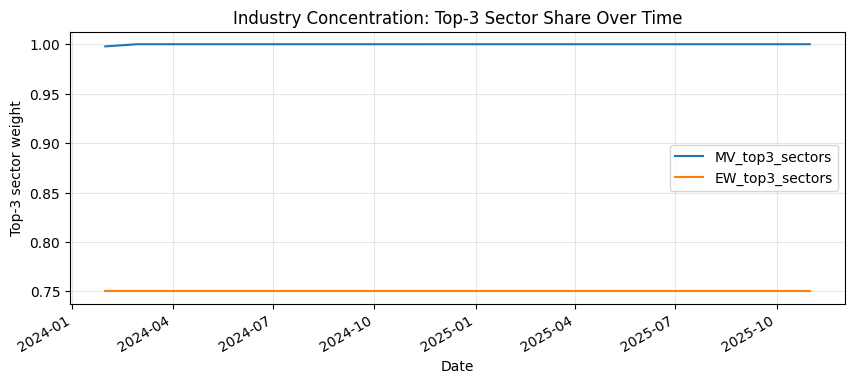

In [67]:
ax = top3.plot(figsize=(10,4))
ax.set_title("Industry Concentration: Top-3 Sector Share Over Time")
ax.set_xlabel("Date")
ax.set_ylabel("Top-3 sector weight")
ax.grid(True, alpha=0.3)
plt.show()

**Top-3 sector share (industry concentration)**

To summarize industry concentration, we track the **top-3 sector share** over time. EW is constant at **0.75**, since three out of four equally weighted sectors represent 75% of the portfolio. MV is close to **1.0** for most dates, meaning that the portfolio’s capital is effectively allocated to only three sectors (or fewer) and at least one sector receives negligible weight. This confirms that MV tends to be more **industry-concentrated** than EW in our setting, reinforcing the trade-off between optimization-driven performance and sector-level diversification.

### Portfolio internal correlation

To capture “clustering risk” beyond weights, we compute a portfolio-level internal correlation measure at each rebalance date. Intuitively, a portfolio with high average pairwise correlation among its holdings has lower diversification potential, even if it holds multiple assets.

We estimate correlations using the same rolling lookback window used for MV estimation, and compute the **weighted average pairwise correlation** implied by the portfolio weights.

In [68]:
def internal_avg_corr(weights_named: pd.Series, corr_mat: pd.DataFrame) -> float:
    """
    Weighted average pairwise correlation excluding diagonal.
    Uses weights w_i w_j as pair weights.
    """
    w = weights_named.reindex(corr_mat.index).fillna(0.0).values
    C = corr_mat.values.copy()
    np.fill_diagonal(C, 0.0)

    num = (w[:, None] * w[None, :] * C).sum()
    den = (w[:, None] * w[None, :]).sum() - np.sum(w**2)  # sum_{i!=j} w_i w_j
    return float(num / den) if den > 0 else np.nan

internal_corr = pd.DataFrame(index=w_mv_named.index, columns=["EW_internal_corr","MV_internal_corr"], dtype=float)

for d in w_mv_named.index:
    loc = rets_named.index.get_loc(d)  # rets_named has daily index
    window_idx = rets_named.index[loc - lookback: loc]
    corr_window = rets_named.loc[window_idx].corr()

    internal_corr.loc[d, "EW_internal_corr"] = internal_avg_corr(w_ew_named.loc[d], corr_window)
    internal_corr.loc[d, "MV_internal_corr"] = internal_avg_corr(w_mv_named.loc[d], corr_window)

internal_corr.tail().round(4)

,EW_internal_corr,MV_internal_corr
2025-04-30,0.4902,0.4625
2025-06-30,0.4893,0.4263
2025-07-31,0.4775,0.4063
2025-09-30,0.4853,0.4730
2025-10-31,0.4394,0.4452


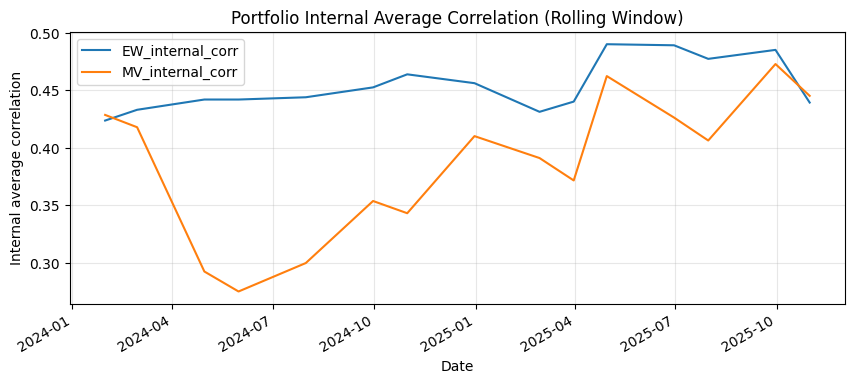

In [69]:
ax = internal_corr.plot(figsize=(10,4))
ax.set_title("Portfolio Internal Average Correlation (Rolling Window)")
ax.set_xlabel("Date")
ax.set_ylabel("Internal average correlation")
ax.grid(True, alpha=0.3)
plt.show()

MV tends to exhibit a **lower internal average correlation** than EW across much of the sample, indicating reduced co-movement among its holdings (i.e., less clustering risk) in several rebalancing windows. The gap is particularly visible in mid-2024, where MV internal correlation drops well below EW, suggesting that the optimizer is actively benefiting from lower-correlation combinations. However, this advantage is **time-varying**: in late 2025 the two series become closer and MV can occasionally match or slightly exceed EW (e.g., 2025-10-31). Overall, MV appears to improve diversification in a **covariance sense** in many periods, even though it is more concentrated in weights and sectors.

## Robustness

Mean–variance portfolios are highly sensitive to estimation error in expected returns and covariances, which can lead to extreme and unstable allocations. Since our capped MV solution frequently hits the 35% maximum weight constraint, we run a **cap-free** variant as a robustness check. The goal is to quantify how much the cap affects (i) performance metrics and (ii) diversification outcomes (concentration and turnover), and to assess whether the strategy’s conclusions remain consistent under a less constrained specification.

In [24]:
w_mv_nocap = pd.DataFrame(index=rebalance_dates, columns=assets, dtype=float)

for d in rebalance_dates:
    loc = rets.index.get_loc(d)
    window_idx = rets.index[loc - lookback: loc]
    window_prices = prices.loc[window_idx]

    mu = expected_returns.mean_historical_return(window_prices, frequency=252)
    S  = risk_models.CovarianceShrinkage(window_prices).ledoit_wolf()

    ef = EfficientFrontier(mu, S, weight_bounds=(0.0, 1.0))
    try:
        ef.max_sharpe(risk_free_rate=rf)
    except exceptions.OptimizationError:
        ef = EfficientFrontier(mu, S, weight_bounds=(0.0, 1.0))
        ef.min_volatility()

    w = ef.clean_weights()
    w_mv_nocap.loc[d] = pd.Series(w).reindex(assets).fillna(0.0)

mv_port_nocap = weights_to_daily_portfolio_returns(rets, w_mv_nocap)

w_mv_cap_named   = w_mv.rename(columns=name_map)        
w_mv_nocap_named = w_mv_nocap.rename(columns=name_map)   

In [25]:
rows = []
for name, series in [("EW", ew_port), ("MV (cap 35%)", mv_port), ("MV (no cap)", mv_port_nocap)]:
    ar, av, sh, mdd = ann_metrics(series.dropna(), rf=rf)
    rows.append([name, ar, av, sh, mdd])

robust_metrics = pd.DataFrame(rows, columns=["Portfolio","Ann Return","Ann Vol","Sharpe","Max Drawdown"])
robust_metrics

,Portfolio,Ann Return,Ann Vol,Sharpe,Max Drawdown
0,EW,0.269376,0.238981,1.127186,-0.214088
1,MV (cap 35%),0.314784,0.222940,1.411965,-0.196046
2,MV (no cap),0.407239,0.215112,1.893151,-0.206077


In [26]:
def hhi(row: pd.Series) -> float:
    w = row.fillna(0).values
    return float(np.sum(w**2))

N_assets = w_mv_cap_named.shape[1]

conc_rb = pd.DataFrame(index=w_mv_cap_named.index)
conc_rb["MV_cap_HHI"]   = w_mv_cap_named.apply(hhi, axis=1)
conc_rb["MV_nocap_HHI"] = w_mv_nocap_named.apply(hhi, axis=1)
conc_rb["EW_HHI"]       = 1 / N_assets

conc_rb["MV_cap_effN"]   = 1 / conc_rb["MV_cap_HHI"]
conc_rb["MV_nocap_effN"] = 1 / conc_rb["MV_nocap_HHI"]
conc_rb["EW_effN"]       = 1 / conc_rb["EW_HHI"]

conc_rb.tail().round(4)

,MV_cap_HHI,MV_nocap_HHI,EW_HHI,MV_cap_effN,MV_nocap_effN,EW_effN
2025-04-30,0.2961,0.6099,0.125,3.3768,1.6397,8.0
2025-06-30,0.2838,0.5744,0.125,3.5232,1.7409,8.0
2025-07-31,0.2867,0.4484,0.125,3.4886,2.2301,8.0
2025-09-30,0.2908,0.6063,0.125,3.4392,1.6494,8.0
2025-10-31,0.3186,0.6521,0.125,3.1391,1.5335,8.0


In [27]:
turnover_cap   = (w_mv.diff().abs().sum(axis=1) / 2).dropna()
turnover_nocap = (w_mv_nocap.diff().abs().sum(axis=1) / 2).dropna()

turnover_summary = pd.DataFrame({
    "MV cap 35%": turnover_cap.describe(),
    "MV no cap":  turnover_nocap.describe()
})

turnover_summary

,MV cap 35%,MV no cap
count,15.000000,15.000000
mean,0.139800,0.144960
std,0.165285,0.136980
min,0.000000,0.000000
25%,0.010605,0.032795
50%,0.099970,0.124860
75%,0.216510,0.233108
max,0.610020,0.386475


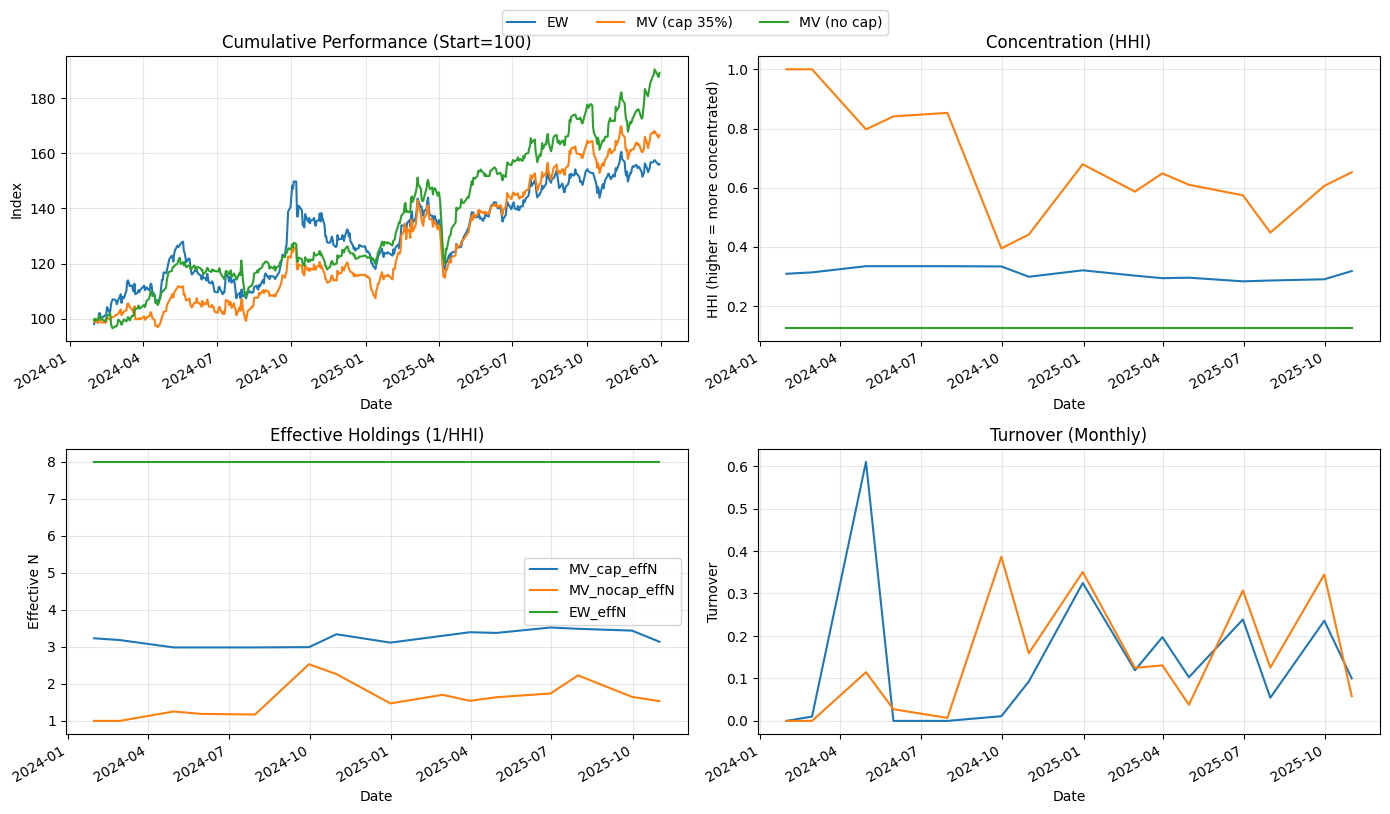

In [44]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

cum_rb = pd.DataFrame({
    "EW": (1 + ew_port).cumprod() * 100,
    "MV (cap 35%)": (1 + mv_port).cumprod() * 100,
    "MV (no cap)": (1 + mv_port_nocap).cumprod() * 100,
})
cum_rb.plot(ax=axes[0, 0], legend=False)
axes[0, 0].set_title("Cumulative Performance (Start=100)")
axes[0, 0].set_xlabel("Date")
axes[0, 0].set_ylabel("Index")
axes[0, 0].grid(True, alpha=0.3)

conc_rb[["MV_cap_HHI", "MV_nocap_HHI", "EW_HHI"]].plot(ax=axes[0, 1], legend=False)
axes[0, 1].set_title("Concentration (HHI)")
axes[0, 1].set_xlabel("Date")
axes[0, 1].set_ylabel("HHI (higher = more concentrated)")
axes[0, 1].grid(True, alpha=0.3)

conc_rb[["MV_cap_effN", "MV_nocap_effN", "EW_effN"]].plot(ax=axes[1, 0], legend=True)
axes[1, 0].set_title("Effective Holdings (1/HHI)")
axes[1, 0].set_xlabel("Date")
axes[1, 0].set_ylabel("Effective N")
axes[1, 0].grid(True, alpha=0.3)

turnover_cmp = pd.DataFrame({
    "MV cap 35%": turnover_cap,
    "MV no cap": turnover_nocap
})
turnover_cmp.plot(ax=axes[1, 1], legend=False)
axes[1, 1].set_title("Turnover (Monthly)")
axes[1, 1].set_xlabel("Date")
axes[1, 1].set_ylabel("Turnover")
axes[1, 1].grid(True, alpha=0.3)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.02))

plt.tight_layout()
plt.show()

**Robustness results: impact of removing the weight cap (cap-free MV)**

The robustness check shows that **removing the 35% weight cap materially changes both performance and diversification**. In terms of performance, EW achieves an annualized return of **26.9%** (Sharpe **1.13**), while MV with the 35% cap improves risk-adjusted results (annualized return **31.5%**, Sharpe **1.41**, and a smaller max drawdown of **−19.6%**). The **cap-free MV** variant delivers the strongest backtested performance (annualized return **40.7%**, Sharpe **1.89**), but this comes with a clear loss of diversification.

Concentration metrics confirm that the cap is a key stabilizing constraint. EW has constant HHI **0.125** (effective holdings **8**). MV with the cap remains significantly more concentrated than EW (HHI around **0.28–0.32**, effective holdings about **3.1–3.5**). Without the cap, HHI increases sharply to roughly **0.45–0.65**, implying only **~1.5–2.2 effective holdings**—i.e., the optimizer effectively behaves like a “1–2 stock” portfolio. This explains why the cap-free MV path can outperform in-sample, but also suggests higher fragility and reduced diversification.

Finally, turnover is comparable across the two MV specifications: average monthly turnover is **~0.14** for both, with the cap-free version showing a slightly higher median but lower maximum spike (cap-free max ≈ **0.39** vs **0.61** under the cap). Overall, the results highlight a central trade-off: **the cap improves diversification and reduces extreme concentration**, while the unconstrained MV can achieve higher backtested performance by taking much more concentrated bets.

## Benchmark comparison: EW and MV vs Hang Seng Index (HSI)

To contextualize portfolio performance, we compare EW and MV against a broad market benchmark: the Hang Seng Index (HSI). We evaluate relative performance by plotting cumulative indices (Start=100) on a common date range and computing the same risk–return metrics. We also report simple market-exposure diagnostics (correlation and beta vs HSI) to understand how much each strategy’s returns co-move with the benchmark.

In [36]:
benchmark_ticker = "^HSI"

bench_raw = yf.download(benchmark_ticker, start=start, end=end, auto_adjust=False, progress=False)
bench_px = bench_raw["Adj Close"].dropna().sort_index()
bench_ret = bench_px.pct_change().dropna()

common = ew_port.index.intersection(mv_port.index).intersection(bench_ret.index)
ew_b = ew_port.loc[common]
mv_b = mv_port.loc[common]
bench_b = bench_ret.loc[common]

print("Common backtest range:", common.min(), "->", common.max(), "| N days:", len(common))

Common backtest range: 2024-01-31 00:00:00 -> 2025-12-30 00:00:00 | N days: 470


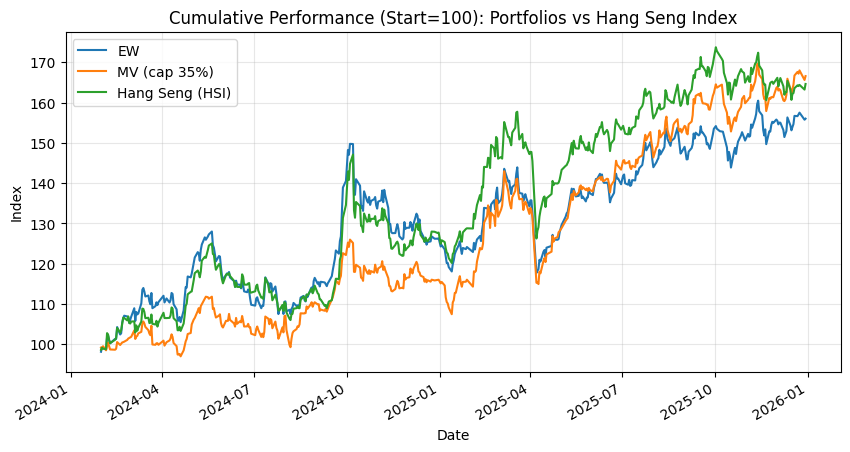

In [37]:
bench_b = bench_b.iloc[:, 0]
cum_bench = pd.DataFrame({
    "EW": (1 + ew_b).cumprod() * 100,
    "MV (cap 35%)": (1 + mv_b).cumprod() * 100,
    "Hang Seng (HSI)": (1 + bench_b).cumprod() * 100,
})

ax = cum_bench.plot(figsize=(10,5))
ax.set_title("Cumulative Performance (Start=100): Portfolios vs Hang Seng Index")
ax.set_xlabel("Date")
ax.set_ylabel("Index")
ax.grid(True, alpha=0.3)
plt.show()

In [38]:
rows = []
for name, series in [("EW", ew_b), ("MV (cap 35%)", mv_b), ("Hang Seng (HSI)", bench_b)]:
    ar, av, sh, mdd = ann_metrics(series.dropna(), rf=rf)
    rows.append([name, ar, av, sh, mdd])

bench_metrics = pd.DataFrame(rows, columns=["Series","Ann Return","Ann Vol","Sharpe","Max Drawdown"])
bench_metrics

,Series,Ann Return,Ann Vol,Sharpe,Max Drawdown
0,EW,0.269376,0.238981,1.127186,-0.214088
1,MV (cap 35%),0.314784,0.222940,1.411965,-0.196046
2,Hang Seng (HSI),0.306483,0.244990,1.251005,-0.199540


In [39]:
def beta_vs_benchmark(r, b):
    return np.cov(r, b)[0,1] / np.var(b)

exposure = pd.DataFrame(index=["EW", "MV (cap 35%)"], columns=["Corr vs HSI", "Beta vs HSI"], dtype=float)
exposure.loc["EW", "Corr vs HSI"] = ew_b.corr(bench_b)
exposure.loc["EW", "Beta vs HSI"] = beta_vs_benchmark(ew_b.values, bench_b.values)

exposure.loc["MV (cap 35%)", "Corr vs HSI"] = mv_b.corr(bench_b)
exposure.loc["MV (cap 35%)", "Beta vs HSI"] = beta_vs_benchmark(mv_b.values, bench_b.values)

exposure.round(3)

,Corr vs HSI,Beta vs HSI
EW,0.927,0.906
MV (cap 35%),0.848,0.773


**Benchmark comparison vs Hang Seng Index (HSI)**

Relative to the Hang Seng Index, the MV strategy delivers the strongest risk-adjusted performance over the common backtest window. While HSI achieves an annualized return of ~30.6% with volatility ~24.5% (Sharpe ~1.25, max drawdown ~−20.0%), the capped MV portfolio attains a slightly higher annualized return (~31.5%) with lower volatility (~22.3%), resulting in a higher Sharpe ratio (~1.41) and a marginally smaller drawdown (~−19.6%). EW is more market-like and shows weaker risk-adjusted performance (Sharpe ~1.13; max drawdown ~−21.4%).

Market-exposure diagnostics reinforce this interpretation. EW has very high correlation and beta versus HSI (corr ~0.93, beta ~0.91), indicating it largely tracks broad market movements. In contrast, MV shows lower correlation and a lower beta (corr ~0.85, beta ~0.77), suggesting that it achieves its performance with **less dependence on the benchmark**, consistent with improved diversification relative to the market.

## Conclusions

Over the evaluated period, the Mean–Variance (MV) strategy improves the **risk–return trade-off** relative to the Equal-Weight (EW) benchmark (higher annualized return and Sharpe, with slightly smaller drawdowns in the capped baseline).  

Diversification diagnostics highlight a clear **trade-off**. In terms of **weight and sector diversification**, EW remains broadly diversified across assets and sectors by construction, while MV is materially more concentrated (lower effective number of holdings and frequent sector tilts). At the same time, MV often achieves lower **internal average correlation** than EW, indicating improved diversification in a **covariance (co-movement) sense** during many windows.  

Benchmarking against the **Hang Seng Index (HSI)** provides additional context. MV delivers a higher Sharpe ratio than HSI over the common window and does so with **lower market exposure** (lower correlation and beta vs HSI), suggesting that the strategy’s performance is not solely explained by riding the market. EW, in contrast, is highly market-like and tracks HSI more closely.

The robustness check confirms that constraints matter: removing the 35% cap increases backtested performance but produces extreme concentration (effective holdings close to 1–2), suggesting reduced diversification and potential fragility. Overall, Markowitz optimization can enhance risk-adjusted performance, but **practical constraints are essential** to control concentration and preserve meaningful diversification.